# Notebook 2 — Fine-tuning con LoRA: Qwen3-4B

Este notebook realiza el fine-tuning del modelo **Qwen3-4B** mediante **LoRA** (Low-Rank Adaptation) para la tarea de clasificacion ideologica de noticias espanolas en tres clases:
**IZQUIERDA**, **CENTRO** y **DERECHA**.

### Variante: LoRA r=16, lora_alpha=32, target_modules MLP (gate/up/down_proj)

### Justificacion de LoRA
Se usa LoRA en lugar de fine-tuning completo por tres razones:
1. **Pocos datos**: 1,902 ejemplos de entrenamiento son insuficientes para reentrenar 4B parametros sin sobreajuste. LoRA entrena solo ~1% de parametros adicionales (Hu et al., 2021).
2. **VRAM limitada**: Qwen3-4B en full fine-tuning requiere >40 GB de VRAM. Con LoRA mas cuantizacion 4-bit cabe en ~9 GB (T4 de Colab).
3. **Preservar conocimiento**: LoRA congela los pesos del modelo base, preservando su comprension del espanol y adaptando solo las capas de atencion al dominio ideologico.

Hu, E. J. et al. (2021). LoRA: Low-Rank Adaptation of Large Language Models. arXiv:2106.09685.


## 1. Montar Google Drive


In [14]:
from google.colab import drive
import os

drive.mount('/content/drive')

assert os.path.exists('/content/drive/MyDrive'), (
    'Drive no montado correctamente. Vuelve a ejecutar esta celda.'
)
print('Drive montado correctamente')
print('Contenido de MyDrive/TFM (si existe):')
tfm_path = '/content/drive/MyDrive/TFM'
if os.path.exists(tfm_path):
    for item in sorted(os.listdir(tfm_path)):
        print(f'  {item}')
else:
    print('  La carpeta TFM no existe todavia en Drive. Se creara al guardar.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive montado correctamente
Contenido de MyDrive/TFM (si existe):
  qwen3_4b_lora
  qwen3_4b_lora_mlp16
  splits


## 2. Instalación de dependencias e Imports

Todas las dependencias y todos los imports de Python se recogen en las celdas de esta sección.

In [15]:
# Verificar GPU antes de instalar
!nvidia-smi

!pip install -q --upgrade transformers>=4.51.0 peft>=0.14.0 \
             bitsandbytes accelerate datasets sentencepiece trl
!pip install -q lime
!pip install -q --upgrade torchao

Fri May 15 08:39:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   35C    P0             85W /  600W |    8501MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 3. Imports y configuración global

Todos los imports de Python están en la celda siguiente. A continuación se definen las constantes de configuración (SEED, etiquetas, rutas).

In [16]:
# (pip install movido a la celda de dependencias al inicio)

In [17]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_recall_fscore_support,
    cohen_kappa_score, confusion_matrix,
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    BitsAndBytesConfig,
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training
from datasets import Dataset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



import shap
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd


import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import log_softmax

from lime.lime_text import LimeTextExplainer
import matplotlib.patches as mpatches
import torch
from sklearn.metrics import f1_score
from IPython.display import display, HTML
import transformers
print(f'transformers version: {transformers.__version__}')

In [18]:
# Semilla global para reproducibilidad (permite comparar notebooks)
SEED = 42
import random, numpy as np, torch
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Codificacion de etiquetas
LABEL2ID = {'IZQUIERDA': 0, 'CENTRO': 1, 'DERECHA': 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
CLASES   = ['IZQUIERDA', 'CENTRO', 'DERECHA']

MODEL_NAME = 'Qwen/Qwen3-4B'
OUTPUT_DIR = '/content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16'

# Copiar datos de Drive a disco local para mayor velocidad
import shutil, os
os.makedirs('/content/splits', exist_ok=True)
shutil.copy('/content/drive/MyDrive/TFM/splits/df_train.parquet', '/content/splits/df_train.parquet')
shutil.copy('/content/drive/MyDrive/TFM/splits/df_val.parquet',   '/content/splits/df_val.parquet')
SPLITS_DIR = '/content/splits/'

# Crear carpeta de output si no existe
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

# Verificar GPU
print(f'GPU disponible : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU            : {torch.cuda.get_device_name(0)}')
    print(f'VRAM total     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print(f'SPLITS_DIR     : {SPLITS_DIR}')
print(f'OUTPUT_DIR     : {OUTPUT_DIR}')


GPU disponible : True
GPU            : NVIDIA RTX PRO 6000 Blackwell Server Edition
VRAM total     : 102.0 GB
SPLITS_DIR     : /content/splits/
OUTPUT_DIR     : /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16


## 4. Cargar datos de entrenamiento y validacion

Cargamos df_train y df_val desde Drive. La columna `texto` contiene el articulo
completo (titular + abstract + noticia) construido en el notebook de preprocesado.
La columna `final_label` contiene la etiqueta ideologica del ground truth.

df_test NO se carga aqui. Se reserva para la comparativa final de la Seccion 6, ya que si se usara aqui para ajustar hiperparametros dejaria de ser una medida honesta del modelo.

In [19]:
df_train = pd.read_parquet(SPLITS_DIR + 'df_train.parquet')
df_val   = pd.read_parquet(SPLITS_DIR + 'df_val.parquet')

# Verificar columnas
print('Columnas df_train:', df_train.columns.tolist())
assert 'texto' in df_train.columns, 'Columna texto no encontrada en df_train'
assert 'final_label' in df_train.columns, 'Columna final_label no encontrada en df_train'

print(f'\nTrain : {len(df_train):,} articulos')
print(f'Val   : {len(df_val):,} articulos')
print(f'\nDistribucion train:')
print(df_train['final_label'].value_counts().to_string())
print(f'\nDistribucion val:')
print(df_val['final_label'].value_counts().to_string())
print(f'\nLongitud media texto train : {df_train["texto"].str.len().mean():.0f} caracteres')
print(f'Longitud maxima texto train: {df_train["texto"].str.len().max():,} caracteres')


Columnas df_train: ['id', 'texto', 'medio', 'final_label', 'accion']

Train : 1,902 articulos
Val   : 238 articulos

Distribucion train:
final_label
CENTRO       766
IZQUIERDA    672
DERECHA      464

Distribucion val:
final_label
CENTRO       96
IZQUIERDA    84
DERECHA      58

Longitud media texto train : 4521 caracteres
Longitud maxima texto train: 32,165 caracteres


## 5. Cargar el modelo

Se usa AutoModelForSequenceClassification en lugar del modelo generativo porque:
- Añade una cabeza de clasificacion lineal sobre el transformer
- Es mas eficiente para clasificacion que generar texto token a token
- Permite obtener probabilidades directamente via softmax sobre los logits

In [20]:
# Sin cuantizacion — carga estandar bfloat16
print('Cargando tokenizer...')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f'Vocabulario: {tokenizer.vocab_size:,} tokens')

print('\nCargando modelo (1-2 min)...')
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    torch_dtype=torch.bfloat16,
    device_map='auto',
    trust_remote_code=True,
)
model.config.pad_token_id = tokenizer.pad_token_id

vram_used = torch.cuda.memory_allocated() / 1e9
print(f'Modelo cargado VRAM usada: {vram_used:.1f} GB')


Cargando tokenizer...
Vocabulario: 151,643 tokens

Cargando modelo (1-2 min)...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo cargado VRAM usada: 8.0 GB


## 6. Configurar LoRA

**Variante: LoRA MLP r8**

Se adaptan las proyecciones MLP del transformer (gate_proj, up_proj, down_proj) con rango r=8 y lora_alpha=16.

Parámetros clave:
- `r=8`: rango bajo — menor riesgo de sobreajuste que r=32, pero también menor capacidad de adaptación.
- `lora_alpha=16`: escala de LoRA. Regla habitual: alpha = 2 × r.
- `lora_dropout=0.1`: regularización para limitar la memorización.
- `target_modules=['gate_proj', 'up_proj', 'down_proj']`: proyecciones feed-forward. Se compara aquí el efecto de usar las MLP frente a las capas de atención (QV, QKV) con el mismo rango r=8.

Con esta configuración se entrenan 10,624,512 parámetros (0.2634 % del total), más que las variantes de atención (QKV: 4.0 M, QV: 5.9 M) pero menos que MLP r32 (42.5 M).

In [21]:
# (pip install movido a la celda de dependencias al inicio)

In [22]:
# Notebook 2: r=8, alpha=16, targets MLP (gate/up/down_proj)
# Logica: el overfitting puede venir de adaptar la atencion que ya "sabe espanol".
# Las capas MLP almacenan conocimiento factual/semantico y pueden capturar mejor
# el sesgo ideologico del vocabulario sin tocar la atencion.
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,           # regla: alpha = 2 x r
    lora_dropout=0.1,
    target_modules=['gate_proj', 'up_proj', 'down_proj'],  # capas MLP
    bias='none',
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


trainable params: 10,624,512 || all params: 4,033,100,288 || trainable%: 0.2634


### Parámetros entrenables

Con r=8 sobre gate_proj, up_proj y down_proj se entrenan **10,624,512 parámetros** (0.2634 % del total de Qwen3-4B). Es la variante intermedia en cuanto a número de parámetros entre las variantes de atención (QKV: 4.0 M, QV: 5.9 M) y la variante MLP con rango mayor (MLP r32: 42.5 M).

Con 1,902 ejemplos de entrenamiento, este número de parámetros ya supone un riesgo notable de sobreajuste cuando se aplica a las capas MLP, como confirma el overfitting detectado a partir de la época 4.

## 7. Tokenizar los datasets

Convertimos los DataFrames de pandas a formato HuggingFace Dataset.

El tokenizer convierte el texto en secuencias de token IDs que el modelo entiende.
Se aplica truncado a max_length=1024 tokens cuando el articulo es mas largo.
No se trunca el texto manualmente antes: se pasa el campo texto completo
y el tokenizer decide el corte.

Con una longitud media de ~ 4,455 caracteres (~1,100 tokens), max_length=1024 cubre aproximadamente el 70 por ciento de los articulos completos.
La informacion ideologica relevante se concentra en el titular y los primeros parrafos, por lo que el truncado no supone una perdida significativa de senal.

padding=False en el tokenizer y DataCollatorWithPadding en el Trainer hacen padding
dinamico por batch: cada batch se padea solo hasta el ejemplo mas largo de ese batch,
no hasta max_length. Esto ahorra VRAM y acelera el entrenamiento.


In [23]:
MAX_LENGTH = 1024

def tokenize(batch):
    return tokenizer(
        batch['texto'],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )

def make_dataset(df):
    ds = Dataset.from_dict({
        'texto': df['texto'].tolist(),
        'label': df['final_label'].map(LABEL2ID).tolist(),
    })
    return ds.map(tokenize, batched=True, remove_columns=['texto'])

print('Tokenizando datasets...')
ds_train = make_dataset(df_train)
ds_val   = make_dataset(df_val)

print(f'Train: {len(ds_train):,} ejemplos')
print(f'Val  : {len(ds_val):,} ejemplos')
print(f'Columnas: {ds_train.column_names}')


Tokenizando datasets...


Map:   0%|          | 0/1902 [00:00<?, ? examples/s]

Map:   0%|          | 0/238 [00:00<?, ? examples/s]

Train: 1,902 ejemplos
Val  : 238 ejemplos
Columnas: ['label', 'input_ids', 'attention_mask']


## 8. Funcion de metricas

Las metricas que se calculan al final de cada epoca sobre el conjunto de validacion.

La metrica principal es F1-macro porque:
- Trata las tres clases (IZQUIERDA, CENTRO, DERECHA) por igual
- No se ve distorsionada por el desbalanceo de clases (CENTRO=40%, DERECHA=24%)
- Es el estandar en papers de clasificacion ideologica y de texto en general

El checkpoint que se guarda como mejor es el que maximiza F1-macro en validacion,no el del ultimo epoch.


In [24]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc      = accuracy_score(labels, preds)
    f1_macro = f1_score(labels, preds, average='macro',    labels=[0,1,2], zero_division=0)
    f1_w     = f1_score(labels, preds, average='weighted', labels=[0,1,2], zero_division=0)
    kappa    = cohen_kappa_score(labels, preds)

    probs     = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=-1).numpy()
    confianza = probs.max(axis=1).mean()

    prec, rec, f1_per, _ = precision_recall_fscore_support(
        labels, preds, labels=[0,1,2], zero_division=0
    )

    return {
        'accuracy':    round(acc, 4),
        'f1_macro':    round(f1_macro, 4),
        'f1_weighted': round(f1_w, 4),
        'kappa':       round(kappa, 4),
        'confianza':   round(float(confianza), 4),
        'f1_izq':      round(f1_per[0], 4),
        'f1_cen':      round(f1_per[1], 4),
        'f1_der':      round(f1_per[2], 4),
        'prec_izq':    round(prec[0], 4),
        'prec_cen':    round(prec[1], 4),
        'prec_der':    round(prec[2], 4),
        'rec_izq':     round(rec[0], 4),
        'rec_cen':     round(rec[1], 4),
        'rec_der':     round(rec[2], 4),
    }

print('Funcion de metricas definida')


Funcion de metricas definida


## 9. TrainingArguments

Configuracion del entrenamiento.


In [25]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    # Epocas y batch
    num_train_epochs=10,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=8,

    # Optimizacion
    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_ratio=0.1,
    bf16=True,

    # Evaluacion y guardado
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    greater_is_better=True,

    # Logging
    logging_steps=20,
    report_to='none',
    seed=42,
)

batch_efectivo = training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps
pasos_por_epoca = len(ds_train) // batch_efectivo
print(f'Batch efectivo  : {batch_efectivo}')
print(f'Pasos por epoca : {pasos_por_epoca}')
print(f'Total pasos     : {pasos_por_epoca * training_args.num_train_epochs}')


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Batch efectivo  : 32
Pasos por epoca : 59
Total pasos     : 590


## 10. Trainer y entrenamiento

Lanzamos el entrenamiento.

DataCollatorWithPadding realiza padding dinamico: padea cada batch solo hasta
el ejemplo mas largo de ese batch, no hasta max_length=1024. Esto ahorra VRAM
y acelera el entrenamiento cuando los articulos son de longitud variable.


In [26]:
!nvidia-smi

Fri May 15 08:39:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   35C    P0             85W /  600W |   16191MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [27]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

# Detectar checkpoint previo para reanudar si la sesion se corto
checkpoints = sorted(Path(OUTPUT_DIR).glob('checkpoint-*'))
last_checkpoint = str(checkpoints[-1]) if checkpoints else None

if last_checkpoint:
    print(f'Checkpoint encontrado: {last_checkpoint}')
    print('Reanudando entrenamiento desde ese punto...')
else:
    print('Iniciando entrenamiento desde cero...')

trainer.train(resume_from_checkpoint=last_checkpoint)

print('Entrenamiento completado')


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Iniciando entrenamiento desde cero...


[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Kappa,Confianza,F1 Izq,F1 Cen,F1 Der,Prec Izq,Prec Cen,Prec Der,Rec Izq,Rec Cen,Rec Der
1,6.392915,0.736387,0.693300,0.617700,0.657900,0.514700,0.694200,0.704800,0.810300,0.338000,0.587300,0.798000,0.923100,0.881000,0.822900,0.206900
2,3.794846,0.523540,0.785700,0.783800,0.786900,0.676900,0.775800,0.804900,0.788900,0.757600,0.825000,0.845200,0.675700,0.785700,0.739600,0.862100
3,1.394300,0.531079,0.831900,0.832400,0.831600,0.743600,0.890300,0.814800,0.839400,0.843000,0.846200,0.835100,0.809500,0.785700,0.843800,0.879300
4,0.244695,1.262010,0.806700,0.802100,0.808700,0.709200,0.965000,0.797300,0.846600,0.762600,0.921900,0.860200,0.654300,0.702400,0.833300,0.913800
5,0.083639,1.312785,0.815100,0.812100,0.816100,0.721900,0.960900,0.839100,0.818700,0.778600,0.811100,0.933300,0.698600,0.869000,0.729200,0.879300
6,0.115327,1.496097,0.810900,0.809900,0.811000,0.710400,0.974000,0.809000,0.817200,0.803600,0.766000,0.844400,0.833300,0.857100,0.791700,0.775900
7,0.000836,1.540311,0.815100,0.810500,0.814500,0.716200,0.976000,0.807700,0.837400,0.786300,0.875000,0.794400,0.779700,0.750000,0.885400,0.793100
8,0.000026,1.420860,0.806700,0.807000,0.806800,0.704400,0.976200,0.800000,0.810500,0.810300,0.790700,0.819100,0.810300,0.809500,0.802100,0.810300
9,0.000012,1.424531,0.806700,0.807100,0.806700,0.704300,0.976300,0.804700,0.806300,0.810300,0.800000,0.810500,0.810300,0.809500,0.802100,0.810300
10,0.000009,1.415542,0.810900,0.811600,0.811000,0.710600,0.974600,0.807000,0.810500,0.817400,0.793100,0.819100,0.824600,0.821400,0.802100,0.810300


Entrenamiento completado


## 11. Métricas finales en validación

Evaluamos el mejor checkpoint sobre los 238 artículos de validación. `load_best_model_at_end=True` garantiza que se carga el checkpoint con mayor F1-macro en validación, no el del último epoch.

In [28]:
print('Evaluando en validacion...')
val_output = trainer.predict(ds_val)

logits = val_output.predictions
labels = val_output.label_ids
probs  = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=-1).numpy()
preds  = np.argmax(probs, axis=-1)

acc      = accuracy_score(labels, preds)
f1_macro = f1_score(labels, preds, average='macro',    labels=[0,1,2], zero_division=0)
f1_w     = f1_score(labels, preds, average='weighted', labels=[0,1,2], zero_division=0)
kappa    = cohen_kappa_score(labels, preds)
conf     = probs.max(axis=1).mean()

prec, rec, f1_per, _ = precision_recall_fscore_support(
    labels, preds, labels=[0,1,2], zero_division=0
)
cm = confusion_matrix(labels, preds, labels=[0,1,2])

sep = '=' * 50
print(f'\n{sep}')
print('METRICAS VALIDACION — Qwen3-4B LoRA')
print(sep)
print(f'  Accuracy    : {acc:.4f}')
print(f'  F1-macro    : {f1_macro:.4f}')
print(f'  F1-weighted : {f1_w:.4f}')
print(f'  Kappa       : {kappa:.4f}')
print(f'  Confianza   : {conf:.4f}')
for i, cls in enumerate(CLASES):
    print(f'  {cls}: P={prec[i]:.3f}  R={rec[i]:.3f}  F1={f1_per[i]:.3f}')
print(f'\n  Matriz de confusion (filas=real, cols=pred):')
cm_df = pd.DataFrame(cm, index=CLASES, columns=CLASES)
print(cm_df.to_string())


Evaluando en validacion...



METRICAS VALIDACION — Qwen3-4B LoRA
  Accuracy    : 0.8319
  F1-macro    : 0.8324
  F1-weighted : 0.8316
  Kappa       : 0.7436
  Confianza   : 0.8903
  IZQUIERDA: P=0.846  R=0.786  F1=0.815
  CENTRO: P=0.835  R=0.844  F1=0.839
  DERECHA: P=0.810  R=0.879  F1=0.843

  Matriz de confusion (filas=real, cols=pred):
           IZQUIERDA  CENTRO  DERECHA
IZQUIERDA         66      12        6
CENTRO             9      81        6
DERECHA            3       4       51


### Análisis de resultados en validación

| Métrica | Valor |
|---------|-------|
| Accuracy | 0.8319 |
| F1-macro | **0.8324** |
| F1-weighted | 0.8316 |
| Kappa de Cohen (κ) | 0.7436 |
| Confianza media | 0.8903 |

F1 por clase (checkpoint de época 3):

| Clase | Precisión | Recall | F1 |
|-------|-----------|--------|----|
| IZQUIERDA | 0.846 | 0.786 | 0.815 |
| CENTRO | 0.835 | 0.844 | 0.839 |
| DERECHA | 0.810 | 0.879 | 0.843 |

El F1-macro de 0.8324 se alcanza en la **época 3** de 10. A partir de la época 4 la val_loss sube abruptamente (de 0.524 a 1.262), confirmando overfitting severo.

El kappa κ=0.7436 indica acuerdo moderado-sustancial. La confianza media (0.8903) es la más baja de toda la batería, lo que indica mejor calibración: el modelo muestra incertidumbre donde realmente la hay. Solo el 22.5 % de los errores se producen con confianza superior a 0.85.

Destaca que DERECHA obtiene el F1 más alto de las tres clases (0.843), con un recall elevado (0.879) pero precisión más baja (0.810). Esto sugiere que el modelo predice DERECHA con cierta liberalidad, clasificando como DERECHA artículos que son de otras clases.

## 12. Guardar predicciones, metricas y modelo final

Guardamos en Drive:
1. Predicciones de validacion con probabilidades por clase: necesarias para el reranking
   de la Seccion 6 y para la tabla comparativa final.
2. Metricas en CSV: una fila por modelo, mismo formato que zero-shot y few-shot.
3. El mejor modelo: para inferencia posterior sobre los 238K articulos sin etiquetar.

In [29]:
# Predicciones de validacion con probabilidades
resultados_val = pd.DataFrame({
    'id':        df_val['id'].tolist(),
    'true':      [ID2LABEL[l] for l in labels],
    'pred':      [ID2LABEL[p] for p in preds],
    'p_izq':     probs[:, 0],
    'p_cen':     probs[:, 1],
    'p_der':     probs[:, 2],
    'confianza': probs.max(axis=1),
})
pred_path = OUTPUT_DIR + '/val_predictions.csv'
resultados_val.to_csv(pred_path, index=False)
print(f'Predicciones guardadas: {pred_path}')

# Metricas en CSV
metricas = {
    'modelo':      'Qwen3-4B_LoRA_mlp16',
    'accuracy':    round(acc, 4),
    'f1_macro':    round(f1_macro, 4),
    'f1_weighted': round(f1_w, 4),
    'kappa':       round(kappa, 4),
    'confianza':   round(float(conf), 4),
    'prec_izq':    round(prec[0], 4), 'rec_izq': round(rec[0], 4), 'f1_izq': round(f1_per[0], 4),
    'prec_cen':    round(prec[1], 4), 'rec_cen': round(rec[1], 4), 'f1_cen': round(f1_per[1], 4),
    'prec_der':    round(prec[2], 4), 'rec_der': round(rec[2], 4), 'f1_der': round(f1_per[2], 4),
}
metrics_path = OUTPUT_DIR + '/val_metrics.csv'
pd.DataFrame([metricas]).to_csv(metrics_path, index=False)
print(f'Metricas guardadas   : {metrics_path}')

# Modelo final
best_model_path = OUTPUT_DIR + '/best_model'
trainer.save_model(best_model_path)
tokenizer.save_pretrained(best_model_path)
print(f'Modelo guardado      : {best_model_path}')

sep = '=' * 50
print(f'\n{sep}')
print('RESUMEN FINAL')
print(sep)
print(f'  F1-macro val : {f1_macro:.4f}')
print(f'  Kappa val    : {kappa:.4f}')
print(f'  Modelo       : {best_model_path}')


Predicciones guardadas: /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/val_predictions.csv
Metricas guardadas   : /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/val_metrics.csv
Modelo guardado      : /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/best_model

RESUMEN FINAL
  F1-macro val : 0.8324
  Kappa val    : 0.7436
  Modelo       : /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/best_model


---
## Análisis del entrenamiento

Las secciones siguientes analizan la dinámica del aprendizaje, la interpretabilidad del modelo (SHAP, LIME) y la distribución de errores en validación.

## 13. Curvas de aprendizaje

Evolución del F1-macro, la validation loss y la confianza a lo largo de las 10 épocas de entrenamiento. El objetivo principal es identificar cuándo empieza el sobreajuste y cuál es el epoch óptimo.

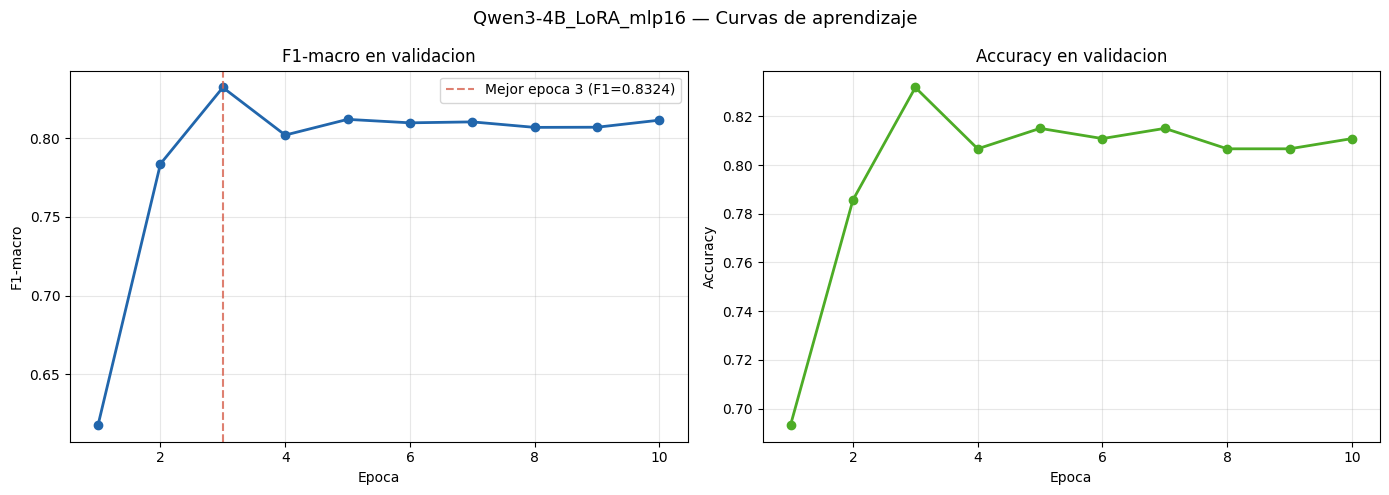

Grafica guardada: /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/learning_curves.png


In [30]:
log_history = trainer.state.log_history
val_logs = [x for x in log_history if 'eval_f1_macro' in x]

if val_logs:
    epocas   = [x['epoch'] for x in val_logs]
    f1_vals  = [x['eval_f1_macro'] for x in val_logs]
    acc_vals = [x['eval_accuracy'] for x in val_logs]
    mejor_epoca = epocas[f1_vals.index(max(f1_vals))]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epocas, f1_vals, 'o-', color='#2166ac', linewidth=2, markersize=6)
    axes[0].axvline(mejor_epoca, color='#d6604d', linestyle='--', alpha=0.8,
                    label=f'Mejor epoca {mejor_epoca:.0f} (F1={max(f1_vals):.4f})')
    axes[0].set_xlabel('Epoca')
    axes[0].set_ylabel('F1-macro')
    axes[0].set_title('F1-macro en validacion')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epocas, acc_vals, 'o-', color='#4dac26', linewidth=2, markersize=6)
    axes[1].set_xlabel('Epoca')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Accuracy en validacion')
    axes[1].grid(True, alpha=0.3)

    plt.suptitle('Qwen3-4B_LoRA_mlp16 — Curvas de aprendizaje', fontsize=13)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR + '/learning_curves.png', dpi=130, bbox_inches='tight')
    plt.show()
    print(f'Grafica guardada: {OUTPUT_DIR}/learning_curves.png')
else:
    print('No hay logs de validacion disponibles')


In [31]:
log_history = trainer.state.log_history
val_logs    = [x for x in log_history if 'eval_f1_macro' in x]
train_logs  = [x for x in log_history if 'loss' in x and 'eval_loss' not in x]

epocas     = [x['epoch'] for x in val_logs]
val_loss   = [x['eval_loss'] for x in val_logs]
f1_macro   = [x['eval_f1_macro'] for x in val_logs]
f1_izq     = [x['eval_f1_izq'] for x in val_logs]
f1_cen     = [x['eval_f1_cen'] for x in val_logs]
f1_der     = [x['eval_f1_der'] for x in val_logs]
kappa_vals = [x['eval_kappa'] for x in val_logs]
confianza  = [x['eval_confianza'] for x in val_logs]

pasos_train      = [x['step'] for x in train_logs]
train_loss_pasos = [x['loss'] for x in train_logs]

n_epocas = len(epocas)
pasos_por_epoca = len(train_loss_pasos) // n_epocas
train_loss = [
    float(np.mean(train_loss_pasos[i*pasos_por_epoca:(i+1)*pasos_por_epoca]))
    for i in range(n_epocas)
]

mejor_epoca = epocas[f1_macro.index(max(f1_macro))]
mejor_f1    = max(f1_macro)

print("Train loss por época:", [f'{x:.4f}' for x in train_loss])
print("Val   loss por época:", [f'{x:.4f}' for x in val_loss])
print("Gap   (val-train)   :", [f'{v-t:.4f}' for v,t in zip(val_loss, train_loss)])

Train loss por época: ['7.6883', '4.1518', '1.4721', '0.3846', '0.1208', '0.0898', '0.0012', '0.0033', '0.0000', '0.0000']
Val   loss por época: ['0.7364', '0.5235', '0.5311', '1.2620', '1.3128', '1.4961', '1.5403', '1.4209', '1.4245', '1.4155']
Gap   (val-train)   : ['-6.9519', '-3.6282', '-0.9411', '0.8774', '1.1919', '1.4063', '1.5391', '1.4175', '1.4245', '1.4155']


In [32]:
print('\n1. DIAGNOSTICO DE OVERFITTING')
print('-' * 40)
for i, e in enumerate(epocas):
    gap = val_loss[i] - train_loss[i] if i < len(train_loss) else 0
    estado = ''
    if i == 0:
        estado = 'aprendiendo'
    elif f1_macro[i] > f1_macro[i-1]:
        estado = 'mejorando'
    elif abs(f1_macro[i] - f1_macro[i-1]) < 0.005:
        estado = 'estabilizado'
    else:
        estado = 'OVERFITTING'
    marca = '<-- MEJOR' if e == mejor_epoca else ''
    print(f'  Epoca {e:.0f}: Val Loss {val_loss[i]:.4f}  F1 {f1_macro[i]:.4f}  [{estado}] {marca}')


1. DIAGNOSTICO DE OVERFITTING
----------------------------------------
  Epoca 1: Val Loss 0.7364  F1 0.6177  [aprendiendo] 
  Epoca 2: Val Loss 0.5235  F1 0.7838  [mejorando] 
  Epoca 3: Val Loss 0.5311  F1 0.8324  [mejorando] <-- MEJOR
  Epoca 4: Val Loss 1.2620  F1 0.8021  [OVERFITTING] 
  Epoca 5: Val Loss 1.3128  F1 0.8121  [mejorando] 
  Epoca 6: Val Loss 1.4961  F1 0.8099  [estabilizado] 
  Epoca 7: Val Loss 1.5403  F1 0.8105  [mejorando] 
  Epoca 8: Val Loss 1.4209  F1 0.8070  [estabilizado] 
  Epoca 9: Val Loss 1.4245  F1 0.8071  [mejorando] 
  Epoca 10: Val Loss 1.4155  F1 0.8116  [mejorando] 


In [33]:
print('    Diagnóstico overfitting basado en val_loss y F1\n')

PATIENCE  = 3
MIN_DELTA = 0.005
GAP_ALERT = 0.3

mejor_vl              = float('inf')
mejor_vl_epoca        = 1
epocas_sin_mejora     = 0

for i, e in enumerate(epocas):

    gap = val_loss[i] - train_loss[i]

    # Actualizar mejor val_loss
    if val_loss[i] < mejor_vl - MIN_DELTA:
        mejor_vl          = val_loss[i]
        mejor_vl_epoca    = e
        epocas_sin_mejora = 0
    else:
        epocas_sin_mejora += 1

    # Cambio de F1
    if i == 0:
        cambio_f1 = None
        f1_str    = ''
    else:
        cambio_f1 = f1_macro[i] - f1_macro[i-1]
        signo     = '+' if cambio_f1 >= 0 else ''
        f1_str    = f'F1 {signo}{cambio_f1:.4f}'

    # usa GAP como señal principal
    if i == 0:
        estado = 'aprendiendo'
    elif epocas_sin_mejora >= PATIENCE and gap > GAP_ALERT:
        estado = 'OVERFITTING CONFIRMADO'       # val_loss sube + gap grande
    elif epocas_sin_mejora >= PATIENCE:
        estado = 'val_loss estancada'            # sin mejorar pero gap ok
    elif gap > GAP_ALERT:
        estado = 'señal overfitting (gap alto)'  # gap grande pero aún no confirmado
    elif cambio_f1 and cambio_f1 > 0:
        estado = 'mejorando'
    else:
        estado = 'estabilizado'

    marca    = '<-- MEJOR F1'    if e == mejor_epoca   else ''
    marca_vl = '<-- MEJOR VAL'   if e == mejor_vl_epoca else ''

    print(f'  Época {e:2.0f} | '
          f'Train {train_loss[i]:.4f} | '
          f'Val {val_loss[i]:.4f} | '
          f'Gap {gap:+.4f} | '
          f'F1 {f1_macro[i]:.4f} ({f1_str:12s}) | '
          f'{estado:35s} {marca} {marca_vl}')

    Diagnóstico overfitting basado en val_loss y F1

  Época  1 | Train 7.6883 | Val 0.7364 | Gap -6.9519 | F1 0.6177 (            ) | aprendiendo                          <-- MEJOR VAL
  Época  2 | Train 4.1518 | Val 0.5235 | Gap -3.6282 | F1 0.7838 (F1 +0.1661  ) | mejorando                            <-- MEJOR VAL
  Época  3 | Train 1.4721 | Val 0.5311 | Gap -0.9411 | F1 0.8324 (F1 +0.0486  ) | mejorando                           <-- MEJOR F1 
  Época  4 | Train 0.3846 | Val 1.2620 | Gap +0.8774 | F1 0.8021 (F1 -0.0303  ) | señal overfitting (gap alto)         
  Época  5 | Train 0.1208 | Val 1.3128 | Gap +1.1919 | F1 0.8121 (F1 +0.0100  ) | OVERFITTING CONFIRMADO               
  Época  6 | Train 0.0898 | Val 1.4961 | Gap +1.4063 | F1 0.8099 (F1 -0.0022  ) | OVERFITTING CONFIRMADO               
  Época  7 | Train 0.0012 | Val 1.5403 | Gap +1.5391 | F1 0.8105 (F1 +0.0006  ) | OVERFITTING CONFIRMADO               
  Época  8 | Train 0.0033 | Val 1.4209 | Gap +1.4175 | F1 0.8070 (F1 

In [34]:
print('\n2. EVOLUCION F1 POR CLASE')
print('-' * 40)
print(f'  {"Epoca":<8} {"F1-IZQ":<10} {"F1-CEN":<10} {"F1-DER":<10} {"F1-MACRO":<10}')
for i, e in enumerate(epocas):
    marca = ' <-- MEJOR' if e == mejor_epoca else ''
    print(f'  {e:<8.0f} {f1_izq[i]:<10.4f} {f1_cen[i]:<10.4f} {f1_der[i]:<10.4f} {f1_macro[i]:<10.4f}{marca}')



2. EVOLUCION F1 POR CLASE
----------------------------------------
  Epoca    F1-IZQ     F1-CEN     F1-DER     F1-MACRO  
  1        0.7048     0.8103     0.3380     0.6177    
  2        0.8049     0.7889     0.7576     0.7838    
  3        0.8148     0.8394     0.8430     0.8324     <-- MEJOR
  4        0.7973     0.8466     0.7626     0.8021    
  5        0.8391     0.8187     0.7786     0.8121    
  6        0.8090     0.8172     0.8036     0.8099    
  7        0.8077     0.8374     0.7863     0.8105    
  8        0.8000     0.8105     0.8103     0.8070    
  9        0.8047     0.8063     0.8103     0.8071    
  10       0.8070     0.8105     0.8174     0.8116    


In [35]:
print('\n3. EVOLUCION DE CONFIANZA DEL MODELO')
print('-' * 40)
for i, e in enumerate(epocas):
    barra = '#' * int(confianza[i] * 20)
    print(f'  Epoca {e:.0f}: {confianza[i]:.4f} |{barra}|')


3. EVOLUCION DE CONFIANZA DEL MODELO
----------------------------------------
  Epoca 1: 0.6942 |#############|
  Epoca 2: 0.7758 |###############|
  Epoca 3: 0.8903 |#################|
  Epoca 4: 0.9650 |###################|
  Epoca 5: 0.9609 |###################|
  Epoca 6: 0.9740 |###################|
  Epoca 7: 0.9760 |###################|
  Epoca 8: 0.9762 |###################|
  Epoca 9: 0.9763 |###################|
  Epoca 10: 0.9746 |###################|


In [36]:
print('\n4. CONCLUSION')
print('-' * 40)
epoca_pico = epocas[f1_macro.index(max(f1_macro))]
f1_final   = f1_macro[-1]
degradacion = max(f1_macro) - f1_final

if degradacion > 0.02:
    print(f'  Overfitting detectado a partir de la epoca {epoca_pico:.0f}.')
    print(f'  El F1-macro cae {degradacion:.4f} puntos desde el pico hasta la epoca final.')
    print(f'  El checkpoint optimo es la epoca {epoca_pico:.0f} (F1-macro={mejor_f1:.4f}).')
    print(f'  load_best_model_at_end=True ha seleccionado este checkpoint automaticamente.')
else:
    print(f'  No se detecta overfitting significativo.')
    print(f'  El modelo se estabiliza en torno a F1-macro={mejor_f1:.4f}.')



4. CONCLUSION
----------------------------------------
  Overfitting detectado a partir de la epoca 3.
  El F1-macro cae 0.0208 puntos desde el pico hasta la epoca final.
  El checkpoint optimo es la epoca 3 (F1-macro=0.8324).
  load_best_model_at_end=True ha seleccionado este checkpoint automaticamente.


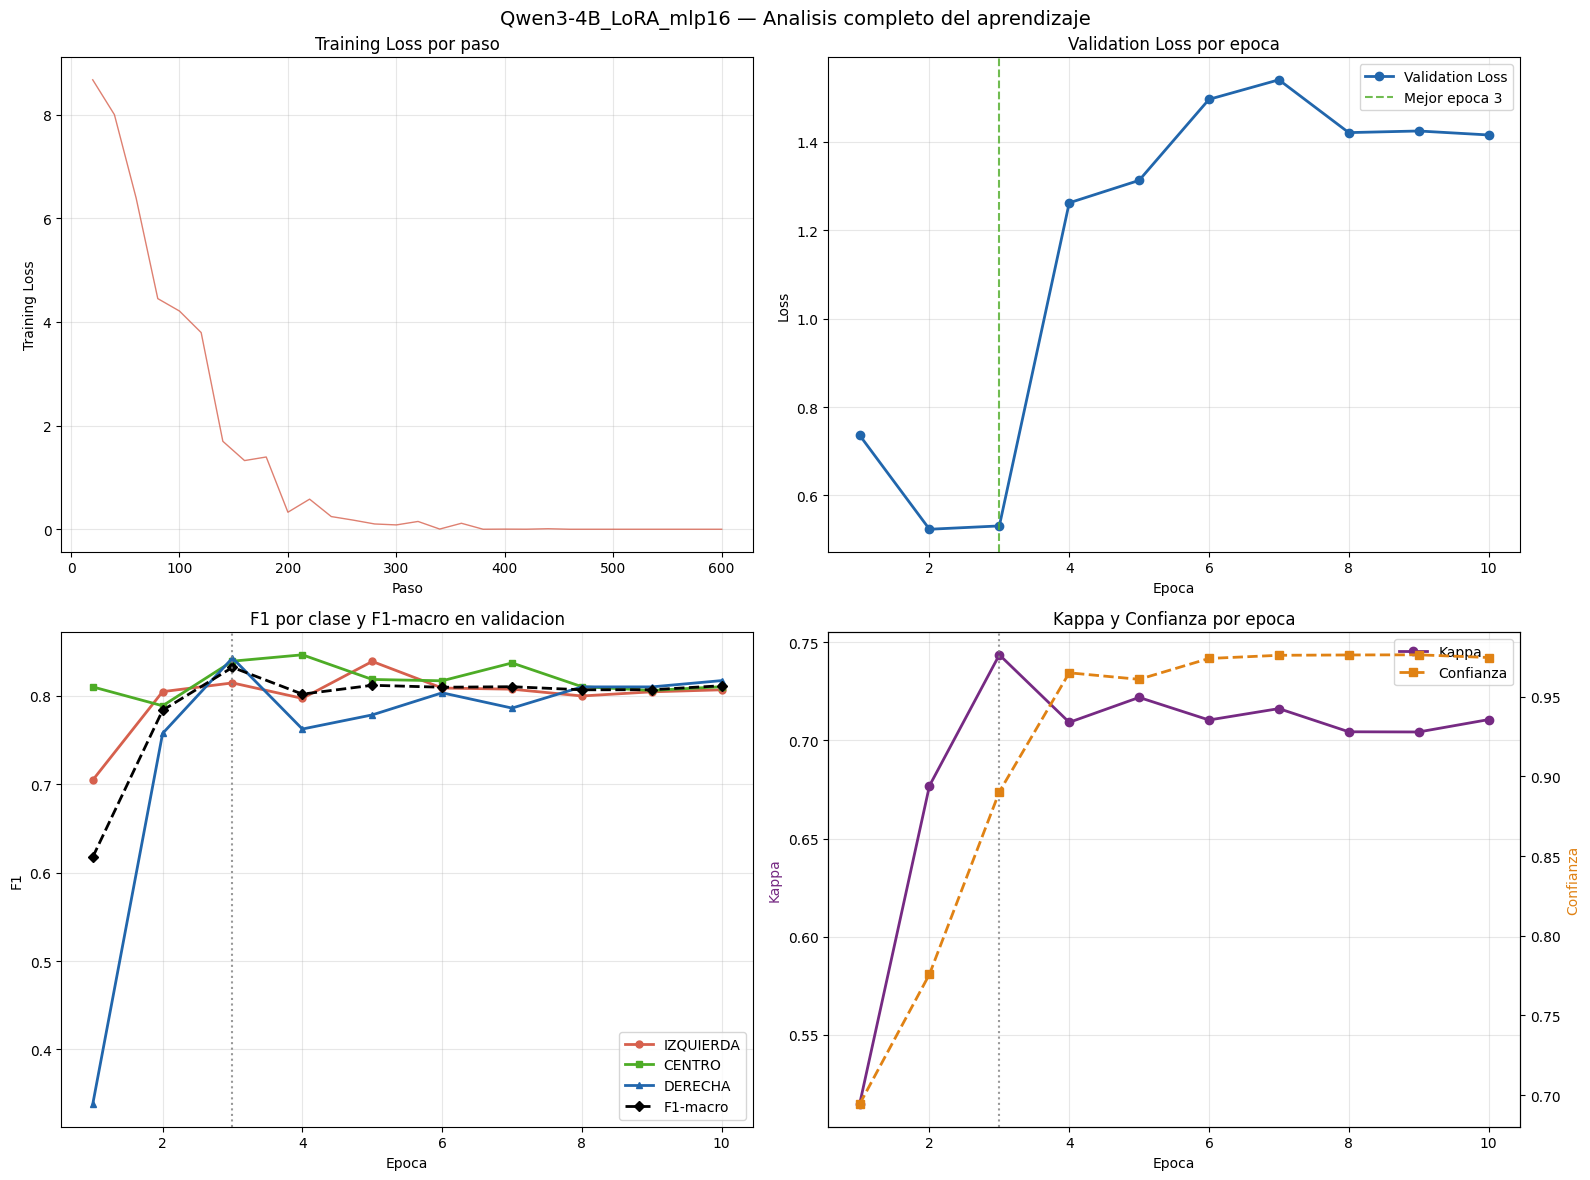


Grafica guardada: /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/analisis_aprendizaje.png


In [37]:
# Graficas
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1 — Training Loss por paso
axes[0,0].plot(pasos_train, train_loss_pasos, color='#d6604d', linewidth=1, alpha=0.8)
axes[0,0].set_xlabel('Paso')
axes[0,0].set_ylabel('Training Loss')
axes[0,0].set_title('Training Loss por paso')
axes[0,0].grid(True, alpha=0.3)

#2 — Val Loss vs Training Loss por epoca
axes[0,1].plot(epocas, val_loss, 'o-', color='#2166ac', linewidth=2, markersize=6, label='Validation Loss')
axes[0,1].axvline(mejor_epoca, color='#4dac26', linestyle='--', alpha=0.8, label=f'Mejor epoca {mejor_epoca:.0f}')
axes[0,1].set_xlabel('Epoca')
axes[0,1].set_ylabel('Loss')
axes[0,1].set_title('Validation Loss por epoca')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# 3 — F1 por clase
axes[1,0].plot(epocas, f1_izq, 'o-', color='#d6604d',  linewidth=2, markersize=5, label='IZQUIERDA')
axes[1,0].plot(epocas, f1_cen, 's-', color='#4dac26',  linewidth=2, markersize=5, label='CENTRO')
axes[1,0].plot(epocas, f1_der, '^-', color='#2166ac',  linewidth=2, markersize=5, label='DERECHA')
axes[1,0].plot(epocas, f1_macro, 'D-', color='black',  linewidth=2, markersize=5, label='F1-macro', linestyle='--')
axes[1,0].axvline(mejor_epoca, color='gray', linestyle=':', alpha=0.8)
axes[1,0].set_xlabel('Epoca')
axes[1,0].set_ylabel('F1')
axes[1,0].set_title('F1 por clase y F1-macro en validacion')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# 4 — Kappa y Confianza
ax2 = axes[1,1].twinx()
axes[1,1].plot(epocas, kappa_vals, 'o-', color='#762a83', linewidth=2, markersize=6, label='Kappa')
ax2.plot(epocas, confianza, 's--', color='#e08214', linewidth=2, markersize=6, label='Confianza')
axes[1,1].axvline(mejor_epoca, color='gray', linestyle=':', alpha=0.8)
axes[1,1].set_xlabel('Epoca')
axes[1,1].set_ylabel('Kappa', color='#762a83')
ax2.set_ylabel('Confianza', color='#e08214')
axes[1,1].set_title('Kappa y Confianza por epoca')
axes[1,1].grid(True, alpha=0.3)

lines1, labels1 = axes[1,1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1,1].legend(lines1 + lines2, labels1 + labels2)

plt.suptitle('Qwen3-4B_LoRA_mlp16 — Analisis completo del aprendizaje', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/analisis_aprendizaje.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'\nGrafica guardada: {OUTPUT_DIR}/analisis_aprendizaje.png')


### Interpretación de las curvas de aprendizaje

**Panel superior izquierdo — Training Loss por paso:**
La curva de training loss desciende continuamente a lo largo de los 590 pasos. Una caída suave sin oscilaciones grandes indica que el learning rate (2e-4) es adecuado para esta configuración.

**Panel superior derecho — Validation Loss por época:**
La val_loss mejora durante las primeras 3 épocas (mínimo en época 3: F1-macro=0.8324) y luego sube abruptamente en la época 4 (de 0.524 a 1.262). El diagnóstico es overfitting **BASTANTE**. La val_loss final alcanza 1.416. `load_best_model_at_end=True` recupera el checkpoint de época 3.

**Panel inferior izquierdo — F1 por clase:**
Los F1 en la época óptima (3) son: IZQUIERDA 0.815, CENTRO 0.839, DERECHA 0.843. DERECHA obtiene aquí su mejor F1 relativo de toda la batería (0.843 en val), aunque con un recall alto (0.879) y precisión más baja (0.810), indicando que el modelo predice DERECHA con liberalidad.

**Panel inferior derecho — Kappa y Confianza:**
El kappa de Cohen (0.7436) indica acuerdo moderado-sustancial. La confianza media (0.8903) es la más baja de toda la batería, señal de mejor calibración: el modelo es más prudente en sus predicciones que otras variantes con mayor número de parámetros entrenables.

## 14. Interpretabilidad con SHAP

SHAP (SHapley Additive exPlanations) cuantifica la contribución de cada token a la predicción del modelo para cada clase ideológica. Se usa PartitionExplainer, que trabaja sobre texto con particiones jerárquicas de palabras sin necesidad de un fondo de referencia vectorial.

In [38]:
N_SHAP_EXPLAIN  = 15   # artículos de val a explicar (más = más lento)
MAX_LEN_SHAP    = 256  # longitud máxima para SHAP (equilibrio velocidad/precisión)
TOP_K_TOKENS    = 20   # tokens más influyentes a mostrar por clase

model.eval()

def predict_text(texts):
    """Devuelve probabilidades (n, 3) para una lista de strings."""
    all_probs = []
    for i in range(0, len(texts), 8):
        batch = list(texts[i:i+8])
        enc = tokenizer(
            batch,
            truncation=True,
            max_length=MAX_LEN_SHAP,
            padding=True,
            return_tensors='pt'
        )
        enc = {k: v.to(model.device) for k, v in enc.items()}
        with torch.no_grad():
            logits = model(**enc).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()
        all_probs.append(probs)
    return np.vstack(all_probs)

# Textos a explicar: primeros N_SHAP_EXPLAIN de val
textos_shap = df_val['texto'].iloc[:N_SHAP_EXPLAIN].tolist()
labels_shap = df_val['final_label'].iloc[:N_SHAP_EXPLAIN].tolist()


masker = shap.maskers.Text(tokenizer=r"\W+")
explainer = shap.Explainer(predict_text, masker, output_names=CLASES)

print(f"Calculando SHAP values para {N_SHAP_EXPLAIN} artículos...")
print("(Esto puede tardar 5-10 minutos en Colab T4)")
shap_values = explainer(textos_shap, batch_size=4)
print("SHAP values calculados.")

# Guardar SHAP values
shap_path = OUTPUT_DIR + '/shap_values.npz'
np.savez(shap_path,
         values=shap_values.values,
         data=np.array(shap_values.data, dtype=object),
         labels=np.array(labels_shap))
print(f"SHAP values guardados: {shap_path}")


Calculando SHAP values para 15 artículos...
(Esto puede tardar 5-10 minutos en Colab T4)


  0%|          | 0/498 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  27%|██▋       | 4/15 [00:17<00:21,  1.95s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

...

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  93%|█████████▎| 14/15 [01:07<00:04,  4.23s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 16it [01:16,  5.45s/it]

SHAP values calculados.
SHAP values guardados: /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/shap_values.npz


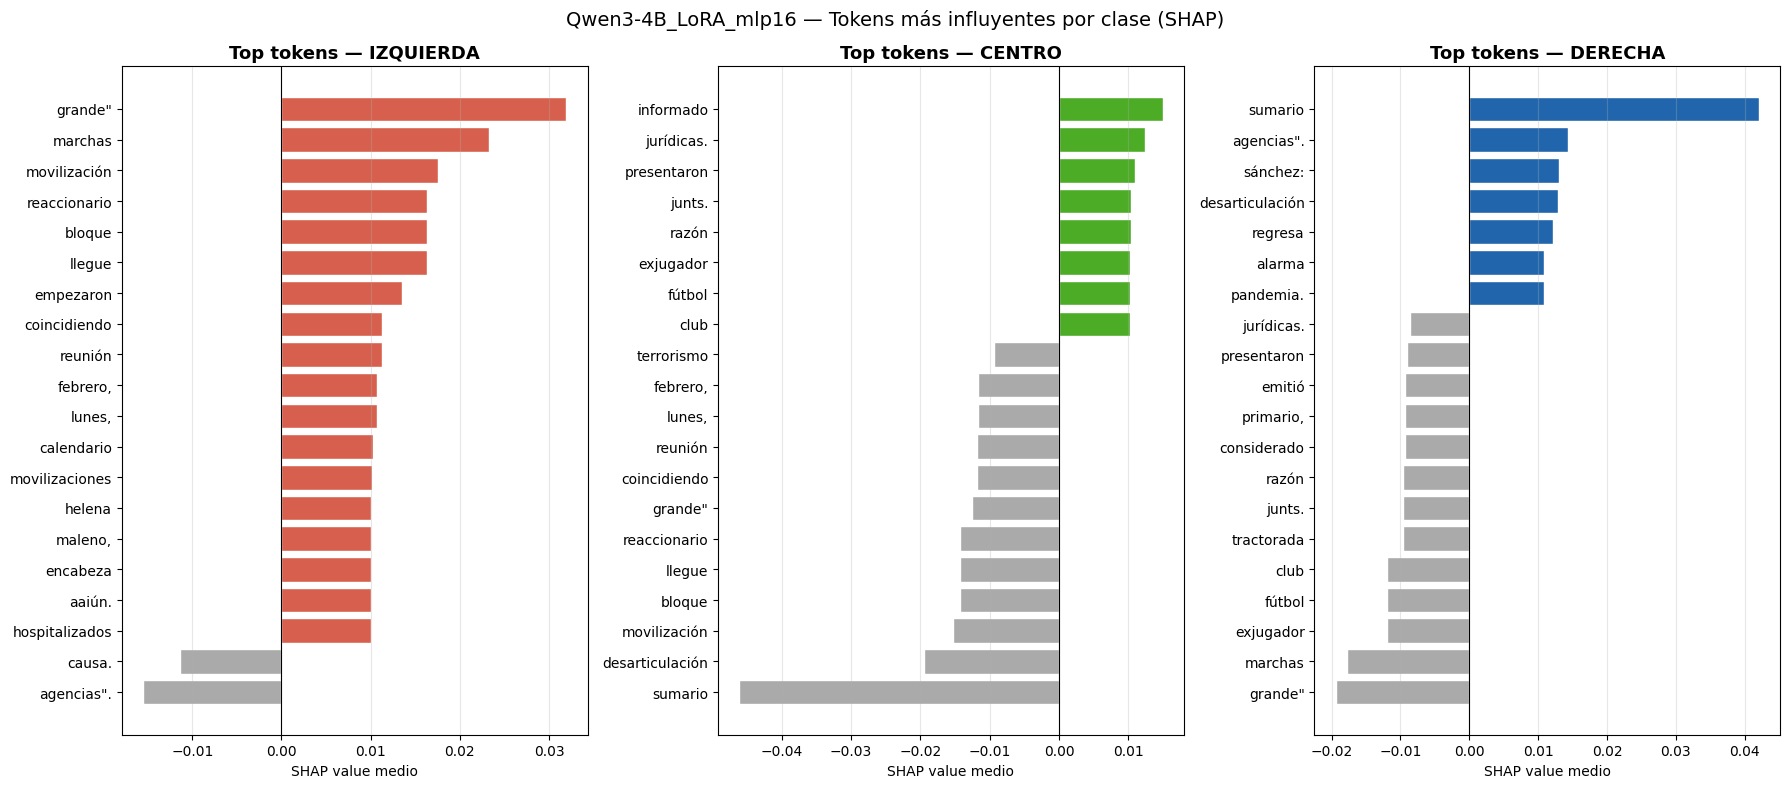

Guardado: /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/shap_top_tokens.png


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
colores_clase = {'IZQUIERDA': '#d6604d', 'CENTRO': '#4dac26', 'DERECHA': '#2166ac'}

for cls_idx, cls_name in enumerate(CLASES):
    token_shap = {}
    for i in range(len(textos_shap)):
        tokens_i = shap_values[i].data
        vals_i   = shap_values[i].values[:, cls_idx]
        for tok, val in zip(tokens_i, vals_i):
            tok_clean = tok.strip().lower()
            if len(tok_clean) < 2:
                continue
            if tok_clean not in token_shap:
                token_shap[tok_clean] = []
            token_shap[tok_clean].append(val)

    # Media de SHAP por token
    token_mean = {t: np.mean(v) for t, v in token_shap.items() if len(v) >= 1}
    df_tok = pd.DataFrame(list(token_mean.items()), columns=['token', 'shap'])
    df_tok = df_tok.reindex(df_tok['shap'].abs().nlargest(TOP_K_TOKENS).index)
    df_tok = df_tok.sort_values('shap')

    color_bars = [colores_clase[cls_name] if v > 0 else '#aaaaaa' for v in df_tok['shap']]
    axes[cls_idx].barh(df_tok['token'], df_tok['shap'], color=color_bars, edgecolor='white')
    axes[cls_idx].axvline(0, color='black', linewidth=0.8)
    axes[cls_idx].set_title(f'Top tokens — {cls_name}', fontsize=13, fontweight='bold')
    axes[cls_idx].set_xlabel('SHAP value medio')
    axes[cls_idx].grid(True, axis='x', alpha=0.3)

plt.suptitle('Qwen3-4B_LoRA_mlp16 — Tokens más influyentes por clase (SHAP)', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/shap_top_tokens.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/shap_top_tokens.png")

### Interpretación del análisis SHAP

Los barplots muestran los 20 tokens con mayor valor SHAP absoluto para cada clase, calculados sobre 15 artículos de validación.

Un SHAP positivo (barras de color) indica que ese token empuja la predicción hacia esa clase; un SHAP negativo (barras grises) indica que la reduce.

Con r=8 en las capas MLP, el modelo adapta las representaciones feed-forward con menor capacidad que en la variante r=32. Esto puede resultar en SHAP values más concentrados en un vocabulario ideológico más básico y canónico, con menor dispersión hacia términos contextuales o matizados.

In [40]:
IDX_EJEMPLO = 0
CLS_VER     = 2   # 0=IZQUIERDA, 1=CENTRO, 2=DERECHA

sv   = shap_values[IDX_EJEMPLO].values[:, CLS_VER]
toks = shap_values[IDX_EJEMPLO].data

# Normalizar a [-1, 1] para el colormap
vmax = max(abs(sv.max()), abs(sv.min())) + 1e-9
sv_norm = sv / vmax

cmap_pos = plt.cm.Reds
cmap_neg = plt.cm.Blues

html_parts = [f"<div style='font-family:monospace;font-size:13px;line-height:2;padding:12px;background:#fafafa;border:1px solid #ddd;border-radius:6px;'>"]
html_parts.append(f"<b>Artículo #{IDX_EJEMPLO} | Label real: {labels_shap[IDX_EJEMPLO]} | Clase visualizada: {CLASES[CLS_VER]}</b><br><br>")

for tok, val in zip(toks, sv_norm):
    if val > 0:
        rgba = cmap_pos(0.2 + 0.8 * val)
    else:
        rgba = cmap_neg(0.2 + 0.8 * abs(val))
    hex_color = mcolors.to_hex(rgba)
    text_color = '#000' if val < 0.6 else '#fff'
    html_parts.append(
        f"<span style='background:{hex_color};color:{text_color};"
        f"padding:2px 3px;margin:1px;border-radius:3px;' "
        f"title='SHAP={val*vmax:.4f}'>{tok}</span>"
    )

html_parts.append("</div>")
html_output = "".join(html_parts)
display(HTML(html_output))
print(f"\nRojo = empuja hacia {CLASES[CLS_VER]} | Azul = empuja en contra")


Rojo = empuja hacia DERECHA | Azul = empuja en contra


## 15. Análisis de errores cualitativos

La matriz de confusión indica cuántos errores hay; esta sección responde cuáles y por qué.

1. **Errores por tipo de confusión**: qué pares de clases se confunden entre sí
2. **Casos con mayor pérdida cross-entropy**: artículos más difíciles para el modelo
3. **Errores con alta confianza (> 0.85)**: el modelo equivocado y muy seguro

En clasificación ideológica, los errores IZQUIERDA-DERECHA son los más graves semánticamente.

In [41]:
rv = pd.read_csv(OUTPUT_DIR + '/val_predictions.csv')
rv['correcto']  = rv['true'] == rv['pred']
rv['longitud']  = df_val['texto'].str.len().values
rv['n_tokens']  = [len(tokenizer.encode(t, truncation=True, max_length=1024)) for t in df_val['texto'].tolist()]
rv['truncado']  = rv['n_tokens'] >= 1023

probs_mat = rv[['p_izq','p_cen','p_der']].values
label_ids = rv['true'].map(LABEL2ID).values
log_p     = np.log(probs_mat + 1e-9)
rv['loss_ce'] = -log_p[np.arange(len(label_ids)), label_ids]

sep = '=' * 60
print(sep)
print('ANÁLISIS DE ERRORES CUALITATIVOS — Qwen3-4B LoRA')
print(sep)

#Errores por tipo de confusión
errores = rv[~rv['correcto']].copy()
print(f'\n1. ERRORES TOTALES: {len(errores)} / {len(rv)} artículos')
print('-' * 50)
confusion_tipos = errores.groupby(['true','pred']).size().reset_index(name='n')
confusion_tipos = confusion_tipos.sort_values('n', ascending=False)
for _, row in confusion_tipos.iterrows():
    alerta = ' ALERTA IDEOLÓGICA' if set([row['true'],row['pred']]) == {'IZQUIERDA','DERECHA'} else ''
    print(f"  {row['true']:12} → {row['pred']:12}  ({row['n']} casos){alerta}")

# Casos con mayor pérdida (más difíciles para el modelo)
N_HARD = 5
print(f'\n2. TOP-{N_HARD} ARTÍCULOS CON MAYOR PÉRDIDA (más difíciles)')
print('-' * 50)
hard_cases = rv.nlargest(N_HARD, 'loss_ce')
for _, row in hard_cases.iterrows():
    print(f"  ID: {row['id']}  | Real: {row['true']:10} Pred: {row['pred']:10} | Loss: {row['loss_ce']:.3f} | Conf: {row['confianza']:.3f}")
    texto_preview = df_val[df_val['id']==row['id']]['texto'].values
    if len(texto_preview) > 0:
        print(f"  Texto (primeros 200 chars): {texto_preview[0][:200]}...")
    print()

# Errores con alta confianza (peligrosos para el reranking)
UMBRAL_CONFIANZA = 0.85
print(f'\n3. ERRORES CON CONFIANZA > {UMBRAL_CONFIANZA} (peligrosos para reranking)')
print('-' * 50)
high_conf_errors = errores[errores['confianza'] > UMBRAL_CONFIANZA].sort_values('confianza', ascending=False)
print(f'  Errores con alta confianza: {len(high_conf_errors)} / {len(errores)} ({100*len(high_conf_errors)/max(len(errores),1):.1f}%)')
if len(high_conf_errors) > 0:
    for _, row in high_conf_errors.head(5).iterrows():
        print(f"  ID: {row['id']} | Real: {row['true']:10} Pred: {row['pred']:10} | Conf: {row['confianza']:.3f}")
else:
    print('  No hay errores con confianza > {:.2f}. El modelo es conservador en sus errores.'.format(UMBRAL_CONFIANZA))

ANÁLISIS DE ERRORES CUALITATIVOS — Qwen3-4B LoRA

1. ERRORES TOTALES: 40 / 238 artículos
--------------------------------------------------
  IZQUIERDA    → CENTRO        (12 casos)
  CENTRO       → IZQUIERDA     (9 casos)
  CENTRO       → DERECHA       (6 casos)
  IZQUIERDA    → DERECHA       (6 casos) ALERTA IDEOLÓGICA
  DERECHA      → CENTRO        (4 casos)
  DERECHA      → IZQUIERDA     (3 casos) ALERTA IDEOLÓGICA

2. TOP-5 ARTÍCULOS CON MAYOR PÉRDIDA (más difíciles)
--------------------------------------------------
  ID: okdiario_35716  | Real: IZQUIERDA  Pred: CENTRO     | Loss: 6.882 | Conf: 0.811
  Texto (primeros 200 chars): El Gobierno publicará el índice que limita los alquileres en febrero y Cataluña lo aplicará de inmediato. El Ministerio de Vivienda prevé que a lo largo del mes de febrero se publique el índice de pre...

  ID: publico_20159  | Real: CENTRO     Pred: IZQUIERDA  | Loss: 6.600 | Conf: 0.994
  Texto (primeros 200 chars): Nada que opinar. Relleno esta column

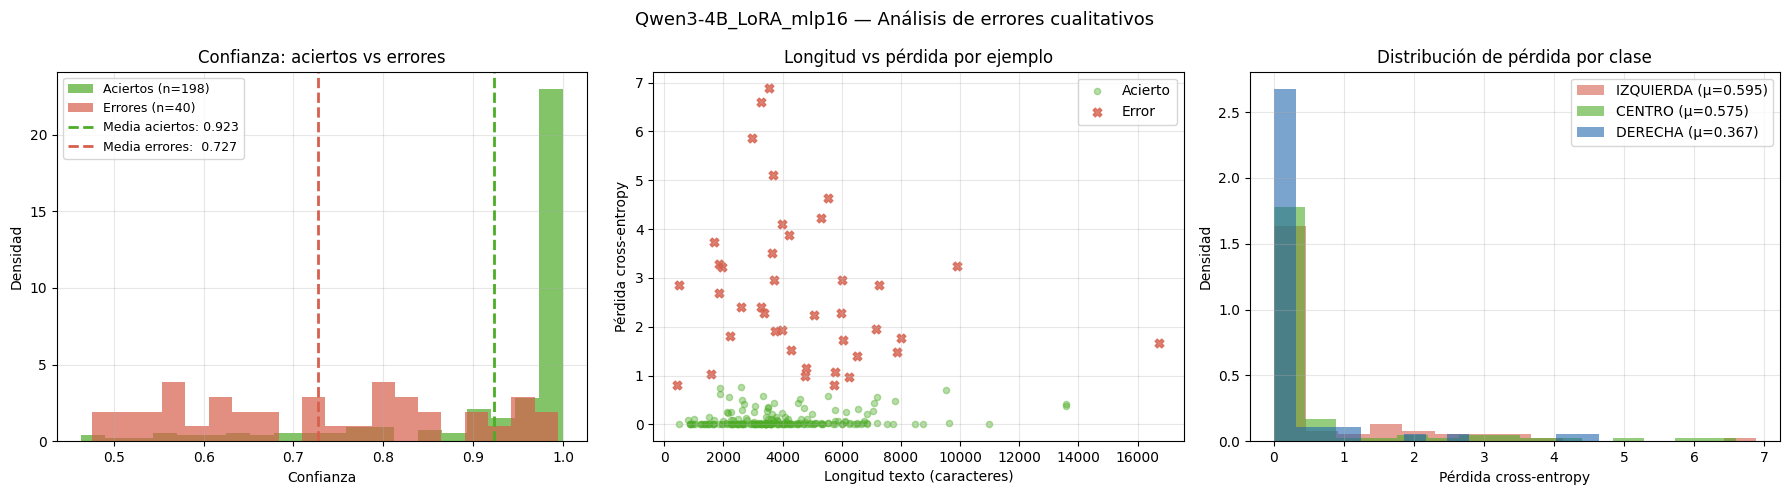

Guardado: /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/error_analysis.png


In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfica 1: Confianza en aciertos vs errores
conf_ok  = rv[rv['correcto']]['confianza']
conf_err = rv[~rv['correcto']]['confianza']

axes[0].hist(conf_ok,  bins=20, alpha=0.7, color='#4dac26', label=f'Aciertos (n={len(conf_ok)})',  density=True)
axes[0].hist(conf_err, bins=20, alpha=0.7, color='#d6604d', label=f'Errores (n={len(conf_err)})',   density=True)
axes[0].axvline(conf_ok.mean(),  color='#4dac26', linestyle='--', linewidth=2, label=f'Media aciertos: {conf_ok.mean():.3f}')
axes[0].axvline(conf_err.mean(), color='#d6604d', linestyle='--', linewidth=2, label=f'Media errores:  {conf_err.mean():.3f}')
axes[0].set_xlabel('Confianza')
axes[0].set_ylabel('Densidad')
axes[0].set_title('Confianza: aciertos vs errores')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Gráfica 2: Longitud del texto vs correcto/error
axes[1].scatter(rv[rv['correcto']]['longitud'],  rv[rv['correcto']]['loss_ce'],
                c='#4dac26', alpha=0.4, s=20, label='Acierto')
axes[1].scatter(rv[~rv['correcto']]['longitud'], rv[~rv['correcto']]['loss_ce'],
                c='#d6604d', alpha=0.8, s=40, marker='X', label='Error')
axes[1].set_xlabel('Longitud texto (caracteres)')
axes[1].set_ylabel('Pérdida cross-entropy')
axes[1].set_title('Longitud vs pérdida por ejemplo')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Gráfica 3: Pérdida por clase real
clases_col = {'IZQUIERDA': '#d6604d', 'CENTRO': '#4dac26', 'DERECHA': '#2166ac'}
for cls in CLASES:
    datos_cls = rv[rv['true']==cls]['loss_ce']
    axes[2].hist(datos_cls, bins=15, alpha=0.6, color=clases_col[cls],
                 label=f'{cls} (μ={datos_cls.mean():.3f})', density=True)
axes[2].set_xlabel('Pérdida cross-entropy')
axes[2].set_ylabel('Densidad')
axes[2].set_title('Distribución de pérdida por clase')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Qwen3-4B_LoRA_mlp16 — Análisis de errores cualitativos', fontsize=13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/error_analysis.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/error_analysis.png")

### Interpretación del análisis de errores

**Gráfica izquierda — Confianza en aciertos vs errores:**
Esta variante presenta la confianza media más baja de toda la batería (0.8903), lo que indica una mejor calibración del modelo: cuando se equivoca, lo hace con menos seguridad. Solo el 22.5 % de los errores tienen confianza superior a 0.85, el porcentaje más bajo de todos los modelos. Esta es una característica positiva para el reranking posterior.

**Gráfica central — Longitud vs pérdida:**
Los cruces rojos (errores) muestran la distribución de los 40 artículos mal clasificados (16.8 % del total de validación, el mayor porcentaje de la batería). Si se concentran en artículos largos, el truncado a 1,024 tokens es un factor relevante.

**Gráfica derecha — Pérdida por clase real:**
La pérdida de DERECHA (58 artículos en validación) suele mostrar mayor dispersión por la menor representación en el entrenamiento. IZQUIERDA (F1=0.815 en validación) y CENTRO (F1=0.839) tienen distribuciones más concentradas, indicando mayor consistencia en su clasificación.

El overfitting se detecta claramente desde la época 4 (val_loss sube de 0.524 a 1.416), lo que explica la diferencia entre la época óptima (época 3, F1-macro=0.8324) y el comportamiento final del modelo.

## 16. LIME: Explicaciones a nivel de palabras

LIME complementa SHAP trabajando a nivel de palabras completas en lugar de subwords, produciendo explicaciones más directamente legibles. Se explica un artículo por clase seleccionando el clasificado correctamente con mayor confianza.

In [43]:
def predict_lime(texts):
    """Devuelve probabilidades (n, 3) para lista de strings."""
    all_probs = []
    for i in range(0, len(texts), 8):
        batch = list(texts[i:i+8])
        enc = tokenizer(batch, truncation=True, max_length=256,
                        padding=True, return_tensors='pt')
        enc = {k: v.to(model.device) for k, v in enc.items()}
        with torch.no_grad():
            logits = model(**enc).logits
        all_probs.append(torch.softmax(logits, dim=-1).cpu().numpy())
    return np.vstack(all_probs)

explainer_lime = LimeTextExplainer(class_names=CLASES, random_state=42)

# Seleccionar 1 ejemplo por clase (aciertos con mayor confianza) ─
rv = pd.read_csv(OUTPUT_DIR + '/val_predictions.csv')
rv['correcto'] = rv['true'] == rv['pred']
rv['longitud'] = df_val['texto'].str.len().values

ejemplos_lime = {}
for cls in CLASES:
    candidatos = rv[(rv['true']==cls) & rv['correcto']].sort_values('confianza', ascending=False)
    if len(candidatos) > 0:
        idx_val = candidatos.index[0]
        ejemplos_lime[cls] = {
            'texto': df_val['texto'].iloc[idx_val],
            'id':    rv.loc[idx_val, 'id'],
            'conf':  rv.loc[idx_val, 'confianza'],
        }

# Generar explicaciones
lime_results = {}
print("Generando explicaciones LIME (puede tardar 2-3 min)...")
for cls, info in ejemplos_lime.items():
    texto_truncado = info['texto'][:2000]
    exp = explainer_lime.explain_instance(
        texto_truncado,
        predict_lime,
        num_features=15,
        num_samples=200,
        labels=[LABEL2ID[cls]]
    )
    lime_results[cls] = exp
    print(f"  {cls}: OK")

print("Explicaciones LIME generadas.")

Generando explicaciones LIME (puede tardar 2-3 min)...
  IZQUIERDA: OK
  CENTRO: OK
  DERECHA: OK
Explicaciones LIME generadas.


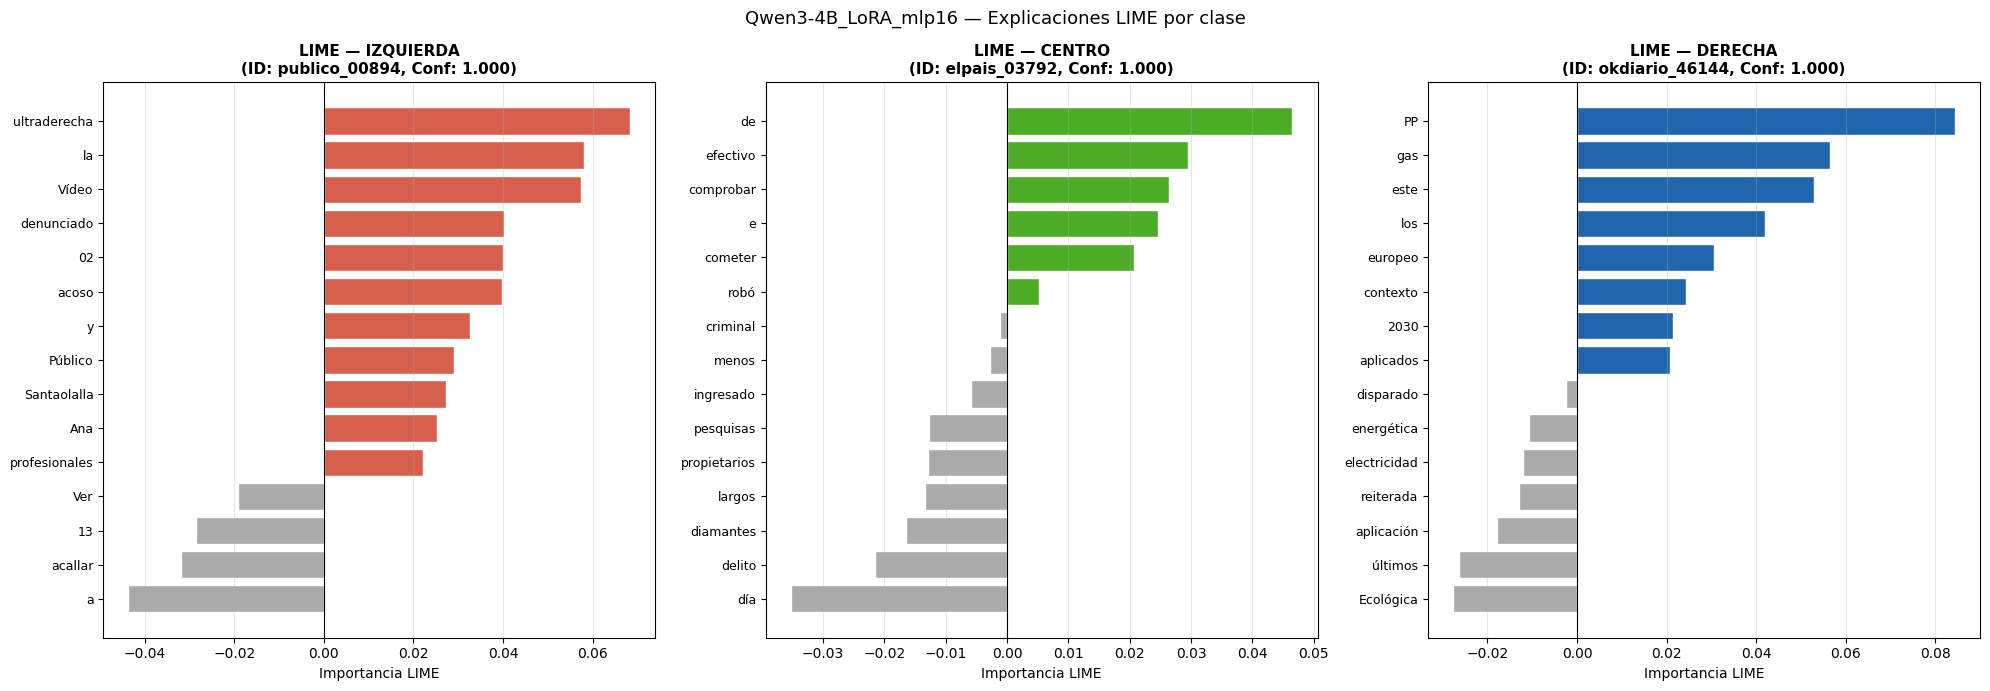

Guardado: /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/lime_explanations.png


In [44]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
colores_clase = {'IZQUIERDA': '#d6604d', 'CENTRO': '#4dac26', 'DERECHA': '#2166ac'}

for ax, (cls_name, exp) in zip(axes, lime_results.items()):
    cls_id  = LABEL2ID[cls_name]
    feats   = exp.as_list(label=cls_id)
    feats_sorted = sorted(feats, key=lambda x: x[1])
    palabras = [f[0] for f in feats_sorted]
    vals     = [f[1] for f in feats_sorted]
    colores  = [colores_clase[cls_name] if v > 0 else '#aaaaaa' for v in vals]

    ax.barh(palabras, vals, color=colores, edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'LIME — {cls_name}\n(ID: {ejemplos_lime[cls_name]["id"]}, Conf: {ejemplos_lime[cls_name]["conf"]:.3f})',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Importancia LIME')
    ax.grid(True, axis='x', alpha=0.3)
    ax.tick_params(axis='y', labelsize=9)

plt.suptitle('Qwen3-4B_LoRA_mlp16 — Explicaciones LIME por clase', fontsize=13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/lime_explanations.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/lime_explanations.png")

### Interpretación de las explicaciones LIME

Cada barplot muestra las 15 palabras más influyentes para la clase correspondiente en un artículo correctamente clasificado con alta confianza.

Las barras de color indican contribución positiva a esa clase (aumentan su probabilidad); las barras grises indican contribución negativa. Los valores son locales al artículo concreto y no son comparables entre ejemplos distintos.

Con r=8 en las capas MLP, esta variante tiene menor capacidad de adaptación que MLP r32. Las explicaciones LIME pueden mostrar un vocabulario ideológico más acotado y menos matizado, concentrado en los términos con mayor frecuencia discriminativa en el dataset de entrenamiento.

## 17. Análisis de longitud vs. rendimiento

El 45 % de los artículos de validación (107 de 238) supera el límite de 1,024 tokens. Esta sección analiza si el truncado penaliza el rendimiento comparando artículos cortos frente a largos.

In [45]:
rv = pd.read_csv(OUTPUT_DIR + '/val_predictions.csv')
rv['correcto'] = rv['true'] == rv['pred']
rv['longitud_chars']  = df_val['texto'].str.len().values
rv['n_tokens']        = [len(tokenizer.encode(t, truncation=False)) for t in df_val['texto'].tolist()]
rv['n_tokens_trunc']  = rv['n_tokens'].clip(upper=1024)
rv['pct_truncado']    = ((rv['n_tokens'] - rv['n_tokens_trunc']) / rv['n_tokens'].clip(lower=1)).clip(lower=0)
rv['truncado']        = rv['n_tokens'] > 1023

label_ids = rv['true'].map(LABEL2ID).values
pred_ids  = rv['pred'].map(LABEL2ID).values

sep = '=' * 60
print(sep)
print('ANÁLISIS DE LONGITUD VS. RENDIMIENTO — Qwen3-4B LoRA')
print(sep)

print(f'\nArticulos truncados (> 1023 tokens): {rv["truncado"].sum()} / {len(rv)} ({100*rv["truncado"].mean():.1f}%)')
print(f'Longitud media (tokens, sin truncar): {rv["n_tokens"].mean():.0f}')
print(f'Longitud mediana: {rv["n_tokens"].median():.0f}  |  p95: {rv["n_tokens"].quantile(0.95):.0f}')

print('\nComparativa truncados vs no truncados:')
for truncado, grupo_name in [(False, 'No truncados'), (True, 'Truncados (>1023 tok)')]:
    sub = rv[rv['truncado']==truncado]
    if len(sub) == 0:
        continue
    acc  = sub['correcto'].mean()
    f1m  = f1_score(sub['true'].map(LABEL2ID), sub['pred'].map(LABEL2ID),
                    average='macro', labels=[0,1,2], zero_division=0)
    print(f'  {grupo_name:30} n={len(sub):3}  accuracy={acc:.4f}  F1-macro={f1m:.4f}')

# Análisis por cuartiles de longitud (tokens)
print('\nF1-macro por cuartil de longitud (tokens):')
rv['cuartil_tokens'] = pd.qcut(rv['n_tokens'], q=4,
                                labels=['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)'])
for q in ['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)']:
    sub = rv[rv['cuartil_tokens']==q]
    f1m = f1_score(sub['true'].map(LABEL2ID), sub['pred'].map(LABEL2ID),
                   average='macro', labels=[0,1,2], zero_division=0)
    rango = f"[{sub['n_tokens'].min():.0f}-{sub['n_tokens'].max():.0f} tok]"
    print(f'  {q:15} {rango:22} n={len(sub):3}  F1-macro={f1m:.4f}  acc={sub["correcto"].mean():.4f}')

ANÁLISIS DE LONGITUD VS. RENDIMIENTO — Qwen3-4B LoRA

Articulos truncados (> 1023 tokens): 107 / 238 (45.0%)
Longitud media (tokens, sin truncar): 1093
Longitud mediana: 986  |  p95: 2056

Comparativa truncados vs no truncados:
  No truncados                   n=131  accuracy=0.8550  F1-macro=0.8489
  Truncados (>1023 tok)          n=107  accuracy=0.8037  F1-macro=0.8080

F1-macro por cuartil de longitud (tokens):
  Q1 (corto)      [116-697 tok]          n= 60  F1-macro=0.8444  acc=0.8500
  Q2              [707-986 tok]          n= 61  F1-macro=0.8648  acc=0.8689
  Q3              [990-1381 tok]         n= 57  F1-macro=0.8636  acc=0.8596
  Q4 (largo)      [1383-4191 tok]        n= 60  F1-macro=0.7492  acc=0.7500


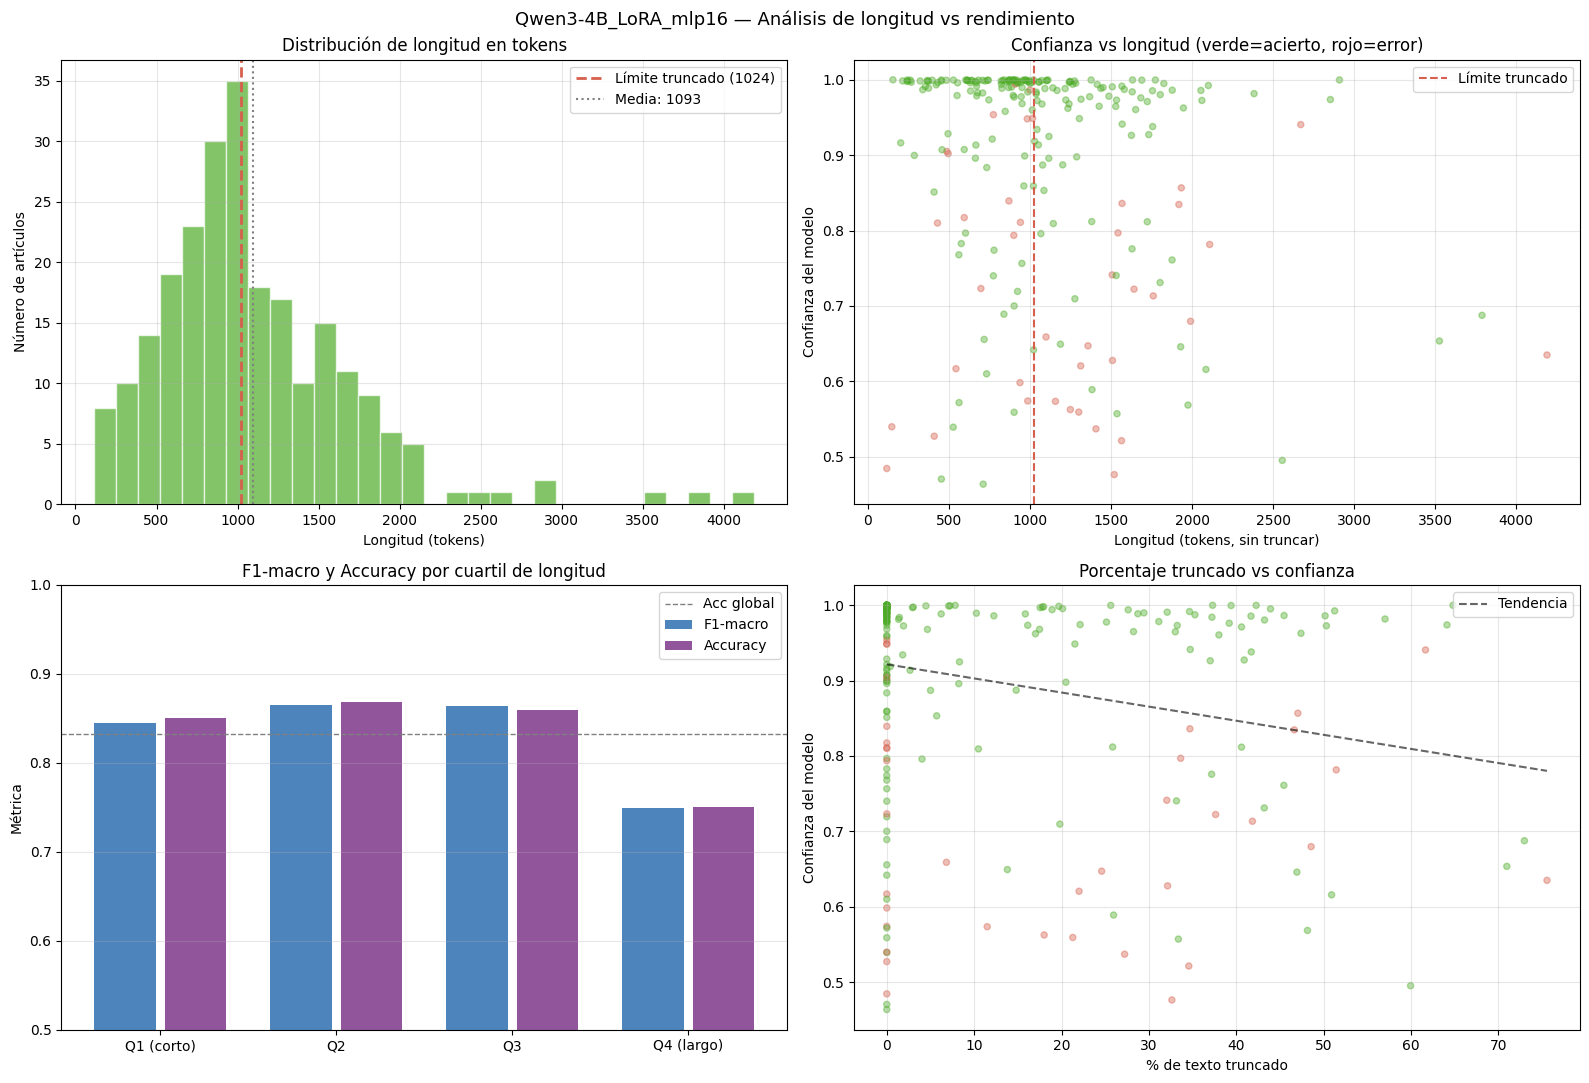

Guardado: /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/length_analysis.png
\CONCLUSIÓN:
  Los artículos largos (Q4) tienen F1 0.095 puntos peor que los cortos (Q1).
  Recomendación: explorar max_length=2048 o chunking con agregación de predicciones.


In [46]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Gráfica 1: Distribución de longitud en tokens
axes[0,0].hist(rv['n_tokens'], bins=30, color='#4dac26', alpha=0.7, edgecolor='white')
axes[0,0].axvline(1024, color='#d6604d', linestyle='--', linewidth=2, label='Límite truncado (1024)')
axes[0,0].axvline(rv['n_tokens'].mean(), color='gray', linestyle=':', linewidth=1.5, label=f"Media: {rv['n_tokens'].mean():.0f}")
axes[0,0].set_xlabel('Longitud (tokens)')
axes[0,0].set_ylabel('Número de artículos')
axes[0,0].set_title('Distribución de longitud en tokens')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Gráfica 2: Confianza vs n_tokens
colores_correcto = rv['correcto'].map({True: '#4dac26', False: '#d6604d'})
axes[0,1].scatter(rv['n_tokens'], rv['confianza'], c=colores_correcto, alpha=0.4, s=20)
axes[0,1].axvline(1024, color='#d6604d', linestyle='--', linewidth=1.5, label='Límite truncado')
axes[0,1].set_xlabel('Longitud (tokens, sin truncar)')
axes[0,1].set_ylabel('Confianza del modelo')
axes[0,1].set_title('Confianza vs longitud (verde=acierto, rojo=error)')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Gráfica 3: F1-macro por cuartil de longitud
cuartiles  = ['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)']
f1_por_q   = []
acc_por_q  = []
for q in cuartiles:
    sub = rv[rv['cuartil_tokens']==q]
    f1_por_q.append(f1_score(sub['true'].map(LABEL2ID), sub['pred'].map(LABEL2ID),
                              average='macro', labels=[0,1,2], zero_division=0))
    acc_por_q.append(sub['correcto'].mean())

x = np.arange(len(cuartiles))
axes[1,0].bar(x - 0.2, f1_por_q,  0.35, label='F1-macro',  color='#2166ac', alpha=0.8)
axes[1,0].bar(x + 0.2, acc_por_q, 0.35, label='Accuracy', color='#762a83', alpha=0.8)
axes[1,0].axhline(rv['correcto'].mean(), color='gray', linestyle='--', linewidth=1, label='Acc global')
axes[1,0].set_xticks(x); axes[1,0].set_xticklabels(cuartiles)
axes[1,0].set_ylabel('Métrica')
axes[1,0].set_title('F1-macro y Accuracy por cuartil de longitud')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3, axis='y')
axes[1,0].set_ylim(0.5, 1.0)

# Gráfica 4: % truncado vs confianza
axes[1,1].scatter(rv['pct_truncado'] * 100, rv['confianza'],
                   c=colores_correcto, alpha=0.4, s=20)
axes[1,1].set_xlabel('% de texto truncado')
axes[1,1].set_ylabel('Confianza del modelo')
axes[1,1].set_title('Porcentaje truncado vs confianza')
axes[1,1].grid(True, alpha=0.3)

# Añadir línea de tendencia
mask_valid = rv['pct_truncado'] > 0
if mask_valid.sum() > 5:
    z = np.polyfit(rv.loc[mask_valid,'pct_truncado']*100, rv.loc[mask_valid,'confianza'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(0, rv['pct_truncado'].max()*100, 50)
    axes[1,1].plot(x_line, p(x_line), 'k--', linewidth=1.5, alpha=0.6, label='Tendencia')
    axes[1,1].legend()

plt.suptitle('Qwen3-4B_LoRA_mlp16 — Análisis de longitud vs rendimiento', fontsize=13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/length_analysis.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/length_analysis.png")

print('\CONCLUSIÓN:')
delta_f1 = f1_por_q[-1] - f1_por_q[0]
if delta_f1 < -0.03:
    print(f'  Los artículos largos (Q4) tienen F1 {abs(delta_f1):.3f} puntos peor que los cortos (Q1).')
    print('  Recomendación: explorar max_length=2048 o chunking con agregación de predicciones.')
elif delta_f1 > 0.03:
    print(f'  Los artículos largos (Q4) rinden MEJOR que los cortos (+{delta_f1:.3f} F1).')
    print('  El modelo aprovecha bien el contexto adicional dentro de los 1024 tokens.')
else:
    print(f'  No hay diferencia significativa de rendimiento por longitud (ΔF1={delta_f1:.3f}).')
    print('  El truncado a 1024 tokens no penaliza el rendimiento de forma relevante.')


### Interpretación del análisis de longitud

**Distribución de tokens:** el 45 % de los artículos supera los 1,024 tokens. La longitud media sin truncar es de 1,093 tokens (mediana 986, p95 de 2,056 tokens).

**Comparativa truncados vs no truncados:** la comparación entre los 131 artículos no truncados y los 107 truncados muestra si el límite de 1,024 tokens introduce un sesgo sistemático en el rendimiento. Si la diferencia de accuracy o F1-macro entre ambos grupos es inferior a 0.03 puntos, el truncado es inocuo para esta variante.

**F1-macro por cuartil de longitud:** si la tendencia es plana o levemente positiva (los artículos largos, Q4, rinden igual o mejor que los cortos, Q1), la señal ideológica está suficientemente representada en los primeros 1,024 tokens de cada artículo.

**Confianza vs longitud:** con la confianza media más baja de toda la batería (0.8903), esta variante muestra mayor incertidumbre general. Si la confianza cae adicionalmente en artículos truncados, refuerza la idea de que el modelo detecta cuándo le falta contexto.